# Model & Backtester Results

This notebook is the results view for the two *separate* historical-testing tracks in
this repo -- they answer different questions, use different data, and must not be
conflated. Full written framing: README's "Data chronology" section and
`paper/nfl_clv_case_study.md` §3.1/§4.5.

## Track A -- calibration backtest (what's actually running today)
`src/model/train.py` + `src/model/calibration.py`, evaluated in this notebook below.
Trains an EPA-based logistic win-probability model on 2015-2024, tests whether its
probabilities are *calibrated* (Brier score, log loss, reliability) against nflverse's
free historical closing lines as the market baseline.

**This is not a CLV backtest.** nflverse only has one closing number per game -- no
intraday snapshots -- so there's no entry-vs-close pair to compute CLV from. It can only
ever tell you "is this model's probability estimate honest," not "would this model have
beaten the sharp close."

## Track B -- the real CLV backtester (not runnable yet)
`src/backtest/engine.py` replays point-in-time Pinnacle snapshots (entry price at a
decision point vs. Pinnacle's close) and settles P&L + CLV for a strategy. It's fully
built and unit-tested against synthetic fixtures (`tests/test_backtest_engine.py`), but
has **never run against real data**, because there isn't any yet: live collection only
started 2026-08-14, and the regular season (the only source of Pinnacle intraday
history this project has or will backfill) doesn't kick off until 2026-09-10. This
notebook doesn't run Track B for that reason -- there's nothing to run it on. It'll get
its own section here once games start settling.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path("..").resolve()
assert (ROOT / "pyproject.toml").exists(), f"unexpected repo root: {ROOT}"

from src.model.baseline import market_baseline
from src.model.calibration import compare_to_baseline, fit_calibrated_model, predict_calibrated_proba
from src.model.evaluate import reliability_curve
from src.model.train import FEATURE_COLUMNS, build_training_frame, fit_win_probability_model, predict_home_win_proba, time_based_split

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

## Loading the historical data + building the training frame

`schedules_2015_2024.parquet` and `pbp_2015_2024.parquet` are nflverse's free static
pulls (`src/features/load_static.py`) -- schedules carry the closing moneyline used as
the market baseline; play-by-play feeds `src/model/features.py`'s leakage-guarded
pre-game EPA features (see `notebooks/`-adjacent `tests/test_features.py` for the
leakage regression test).

In [2]:
schedule = pd.read_parquet(ROOT / "data" / "static" / "schedules_2015_2024.parquet")
pbp = pd.read_parquet(ROOT / "data" / "static" / "pbp_2015_2024.parquet")

training_df = build_training_frame(pbp, schedule)
print(f"{len(training_df)} games with a usable label + full feature set "
      f"(out of {len(schedule)} total games 2015-2024 -- drops ties and week-1-of-season openers)")
training_df[["game_id", "season", "week", "home_team", "away_team", "home_win", "market_prob_home", *FEATURE_COLUMNS]].head()

2595 games with a usable label + full feature set (out of 2743 total games 2015-2024 -- drops ties and week-1-of-season openers)


,game_id,season,week,home_team,away_team,home_win,market_prob_home,home_pre_off_epa,home_pre_off_success,home_pre_def_epa_allowed,home_pre_def_success_allowed,away_pre_off_epa,away_pre_off_success,away_pre_def_epa_allowed,away_pre_def_success_allowed,home_rest,away_rest,div_game
16,2015_02_DEN_KC,2015,2,KC,DEN,0,0.603343,0.002278,0.432836,-0.130424,0.453333,-0.227019,0.333333,-0.362337,0.293103,4,4,1
17,2015_02_NE_BUF,2015,2,BUF,NE,0,0.539928,0.080444,0.357143,0.009576,0.405405,0.290281,0.533333,0.249406,0.513889,7,10,1
18,2015_02_HOU_CAR,2015,2,CAR,HOU,1,0.574035,-0.088671,0.362319,-0.318733,0.378788,-0.130424,0.453333,0.002278,0.432836,7,7,0
19,2015_02_ARI_CHI,2015,2,CHI,ARI,0,0.469433,0.093701,0.458333,0.391846,0.561404,0.210083,0.459016,-0.020548,0.369863,7,7,0
21,2015_02_TEN_CLE,2015,2,CLE,TEN,1,0.517291,-0.237009,0.388060,0.148887,0.457627,0.301102,0.538462,-0.285730,0.328571,7,7,0


## Train / calibrate / test split

Out-of-time by season -- train (2015-2021), calibrate (2022), test (2023-2024) -- so no
season is used for more than one of {fit model, fit calibration, report results}
(`src/model/train.py::time_based_split`).

In [3]:
train_df, calib_df, test_df = time_based_split(
    training_df, train_seasons=range(2015, 2022), calib_seasons=[2022], test_seasons=[2023, 2024]
)
print(f"train={len(train_df)}  calib={len(calib_df)}  test={len(test_df)} games")

raw_model = fit_win_probability_model(train_df)
calibrated_model = fit_calibrated_model(raw_model, calib_df, method="isotonic")

predictions = {
    "market_baseline": test_df["market_prob_home"],
    "raw_logistic": predict_home_win_proba(raw_model, test_df),
    "calibrated_logistic": predict_calibrated_proba(calibrated_model, test_df),
}

train=1743  calib=282  test=570 games


## Results: Brier score & log loss (test seasons, 2023-2024)

Lower is better on both. The market baseline is the floor every model has to beat
(blueprint Part E) -- most models don't, and that's the expected, honest outcome, not a
bug to chase away.

In [4]:
report = compare_to_baseline(predictions, test_df["home_win"])
report

,model,brier,log_loss
0,market_baseline,0.209862,0.608192
1,calibrated_logistic,0.229434,0.651399
2,raw_logistic,0.231590,0.658831


## Reliability curves

Binned predicted probability vs. observed win frequency (`src/model/evaluate.py::reliability_curve`,
10 bins). A perfectly calibrated model sits on the diagonal. Marker size encodes bin
count (`n`) -- a bin near the diagonal built on 3 games means much less than one built
on 150.

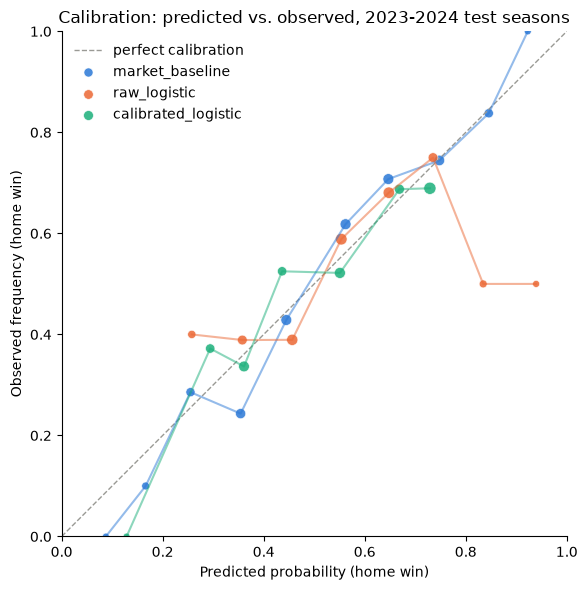

In [5]:
import matplotlib.pyplot as plt

# dataviz skill's categorical slots 1-3 (blue/orange/aqua) -- validated all-pairs CVD-safe
# for exactly 3 series, fixed role assignment (never reassigned if a series is dropped).
COLORS = {
    "market_baseline": "#2a78d6",
    "raw_logistic": "#eb6834",
    "calibrated_logistic": "#1baf7a",
}

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1, color="#9a9a95", label="perfect calibration")

for name, p in predictions.items():
    curve = reliability_curve(np.asarray(p), test_df["home_win"].to_numpy(), n_bins=10).dropna(subset=["predicted", "observed"])
    sizes = 20 + 4 * np.sqrt(curve["count"])
    ax.scatter(curve["predicted"], curve["observed"], s=sizes, color=COLORS[name], label=name, alpha=0.85, edgecolors="white", linewidths=0.5)
    ax.plot(curve["predicted"], curve["observed"], color=COLORS[name], linewidth=1.5, alpha=0.5)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Predicted probability (home win)")
ax.set_ylabel("Observed frequency (home win)")
ax.set_title("Calibration: predicted vs. observed, 2023-2024 test seasons")
ax.set_aspect("equal")
ax.legend(loc="upper left", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## What's driving the model

Standardized logistic regression coefficients (the pipeline scales features before
fitting -- `src/model/train.py::fit_win_probability_model` -- so coefficients are
directly comparable in magnitude). Positive = pushes toward a home win.

In [6]:
coefs = pd.Series(raw_model.named_steps["logit"].coef_[0], index=FEATURE_COLUMNS).sort_values(key=abs, ascending=False)
coefs.to_frame("standardized_coefficient")

,standardized_coefficient
away_pre_off_success,-0.212711
away_pre_off_epa,-0.195362
home_pre_off_success,0.190492
home_pre_def_epa_allowed,-0.189835
away_pre_def_epa_allowed,0.166101
home_pre_off_epa,0.162793
away_pre_def_success_allowed,-0.085390
div_game,-0.075004
away_rest,-0.069657
home_rest,0.048564


## Opponent-adjustment benchmark: Elo

The EPA features above have no opponent adjustment -- a team's rolling EPA looks the
same whether it was earned against a good defense or a bad one. `src/model/elo.py`
adds the standard fix from the sports-analytics literature: FiveThirtyEight-style NFL
Elo, sequential and leakage-free by construction (a team's rating going into a game
only reflects games strictly before it -- Elo doesn't need EPA's shift() trick, the
sequential update *is* the leakage guard). Franchise relocations (SD->LAC, OAK->LV,
STL->LA) are canonicalized so a team's rating carries through a move instead of
resetting to the initial 1500.

Three variants compared below, same train/calib/test split and same test-season
predictions as the EPA-only result above:
- **`elo_raw_no_fit`**: the pure Elo logistic transform (`elo_win_probability`), no
  model fitting at all -- just the rating difference plus home-field advantage.
- **`elo_fitted`**: a 1-feature logistic regression on `home_pre_elo`/`away_pre_elo`
  (barely different from the raw transform, as expected -- there's not much for a
  2-parameter fit to improve on a well-specified 1-dimensional signal).
- **`epa_plus_elo`**: both feature sets combined into one logistic regression.

In [7]:
from src.model.elo import DEFAULT_HOME_FIELD_ADVANTAGE, compute_team_elo_ratings, elo_win_probability
from src.model.train import COMBINED_FEATURE_COLUMNS, ELO_FEATURE_COLUMNS

elo_ratings = compute_team_elo_ratings(schedule)
training_df_elo = build_training_frame(pbp, schedule, elo_ratings=elo_ratings)
train_df_elo, calib_df_elo, test_df_elo = time_based_split(
    training_df_elo, train_seasons=range(2015, 2022), calib_seasons=[2022], test_seasons=[2023, 2024]
)
print(f"train={len(train_df_elo)}  calib={len(calib_df_elo)}  test={len(test_df_elo)} games  (same counts as the EPA-only split above)")

raw_elo_prob = [
    elo_win_probability(row.home_pre_elo, row.away_pre_elo, DEFAULT_HOME_FIELD_ADVANTAGE)
    for row in test_df_elo.itertuples()
]
elo_model = fit_win_probability_model(train_df_elo, feature_columns=ELO_FEATURE_COLUMNS)
combined_model = fit_win_probability_model(train_df_elo, feature_columns=COMBINED_FEATURE_COLUMNS)

elo_report = compare_to_baseline(
    {
        "market_baseline": test_df_elo["market_prob_home"],
        "epa_only": predict_home_win_proba(raw_model, test_df_elo, feature_columns=FEATURE_COLUMNS),
        "elo_raw_no_fit": raw_elo_prob,
        "elo_fitted": predict_home_win_proba(elo_model, test_df_elo, feature_columns=ELO_FEATURE_COLUMNS),
        "epa_plus_elo": predict_home_win_proba(combined_model, test_df_elo, feature_columns=COMBINED_FEATURE_COLUMNS),
    },
    test_df_elo["home_win"],
)
elo_report

train=1743  calib=282  test=570 games  (same counts as the EPA-only split above)


,model,brier,log_loss
0,market_baseline,0.209862,0.608192
1,epa_plus_elo,0.219173,0.630386
2,elo_raw_no_fit,0.220886,0.632857
3,elo_fitted,0.220995,0.633243
4,epa_only,0.231590,0.658831


**Reading this honestly:** Elo alone (0.2209) already beats the full EPA feature set
(0.2316) -- opponent-adjustment on its own is worth more than raw team-level EPA
rolling averages. Combining both (`epa_plus_elo`, 0.2192) closes roughly 57% of the
gap between EPA-only and the market baseline (`(0.2316-0.2192)/(0.2316-0.2099)`).
Still short of the market -- as expected, per the blueprint's own framing -- but a
real, substantial improvement over the previous best model, and the first result in
this project that meaningfully validates the "opponent-adjustment was the biggest
gap" hypothesis rather than just asserting it.

In [8]:
current_elo = compute_team_elo_ratings(schedule)
final_ratings = {}
for row in current_elo.itertuples():
    final_ratings[row.home_team] = row.home_post_elo
    final_ratings[row.away_team] = row.away_post_elo
pd.Series(final_ratings, name="elo_end_of_2024").sort_values(ascending=False).to_frame()

,elo_end_of_2024
PHI,1756.793776
BAL,1704.629770
BUF,1698.143570
KC,1690.246332
DET,1689.959238
GB,1607.356545
MIN,1592.174719
WAS,1588.649080
DEN,1574.453060
LA,1567.733223


## Garbage-time filtering: a negative result

The standard nflverse-community convention for "garbage time" -- 4th quarter or
overtime with win probability outside [0.05, 0.95], i.e. the outcome is no longer
competitively in doubt -- excludes plays that don't reflect real competitive football
(backups in, prevent defense, clock-killing). The hypothesis: EPA computed only on
non-garbage-time plays should be a *cleaner* signal of true team strength.

`src/model/features.py::team_game_epa(..., exclude_garbage_time=True)` implements
this (requires `qtr`, added to the cached play-by-play schema alongside the
already-present `wp` -- see `src/features/load_static.py::PBP_COLUMNS`). Sanity
check before trusting the result: 11.3% of real plays get flagged (matches typical
published estimates), with a real EPA mean shift (garbage-time plays average -0.053
EPA/play vs. 0.013 for competitive snaps) -- the filter is doing something
meaningful, not degenerate.

In [9]:
results = {}
for filt in (False, True):
    df_variant = build_training_frame(pbp, schedule, elo_ratings=elo_ratings, exclude_garbage_time=filt)
    train_v, calib_v, test_v = time_based_split(
        df_variant, train_seasons=range(2015, 2022), calib_seasons=[2022], test_seasons=[2023, 2024]
    )
    epa_model_v = fit_win_probability_model(train_v, feature_columns=FEATURE_COLUMNS)
    combined_model_v = fit_win_probability_model(train_v, feature_columns=COMBINED_FEATURE_COLUMNS)
    label = "garbage_filtered" if filt else "unfiltered"
    results[f"epa_only_{label}"] = predict_home_win_proba(epa_model_v, test_v, feature_columns=FEATURE_COLUMNS)
    results[f"epa_plus_elo_{label}"] = predict_home_win_proba(
        combined_model_v, test_v, feature_columns=COMBINED_FEATURE_COLUMNS
    )
    test_df_for_report = test_v  # same test rows either way (filtering never drops a whole game)

garbage_report = compare_to_baseline({"market_baseline": test_df_for_report["market_prob_home"], **results}, test_df_for_report["home_win"])
garbage_report

,model,brier,log_loss
0,market_baseline,0.209862,0.608192
1,epa_plus_elo_unfiltered,0.219173,0.630386
2,epa_plus_elo_garbage_filtered,0.219672,0.631240
3,epa_only_unfiltered,0.231590,0.658831
4,epa_only_garbage_filtered,0.233508,0.663328


**Honest reading: garbage-time filtering makes both variants slightly *worse*, not
better** (EPA-only: 0.2316 -> 0.2335; EPA+Elo: 0.2192 -> 0.2197). Not the expected
direction, and reported as found rather than reframed. Plausible reasons, stated as
hypotheses rather than proven:
- Removing ~11% of plays shrinks the effective sample behind each team's rolling
  average, especially early-season when the window is already small -- the added
  noise from a smaller sample may outweigh the benefit of a "cleaner" signal.
- Garbage-time EPA is different (lower on average) but not obviously *wrong* --
  a genuinely strong team's backups plausibly still outperform a weak team's, so
  the excluded plays likely still carry real signal about team quality, just with
  a level shift, not pure noise.

**Conclusion: garbage-time filtering is not adopted as a default** for this
feature set -- `exclude_garbage_time` stays opt-in, defaulting to `False`, and
this negative result is the reason, not an oversight.

## Gradient-boosted trees: another negative result

Blueprint Part E named "logistic OR GBM" as the starting options; only logistic had
actually been tried. `src/model/train.py::fit_gbm_model` adds
`sklearn.ensemble.HistGradientBoostingClassifier` -- no new dependency, and no
`StandardScaler` needed (tree splits are scale-invariant, unlike the logistic model).

A small hand-swept grid was run first, since GBM is far more hyperparameter-sensitive
than logistic regression and reporting one arbitrary config would be a weak comparison
either way:

In [10]:
from src.model.evaluate import brier_score
from src.model.train import fit_gbm_model

gbm_sweep_configs = [
    dict(max_iter=200, max_depth=3, learning_rate=0.05, l2_regularization=1.0),
    dict(max_iter=50, max_depth=2, learning_rate=0.1, l2_regularization=1.0),
    dict(max_iter=500, max_depth=2, learning_rate=0.02, l2_regularization=5.0),
    dict(max_iter=100, max_depth=1, learning_rate=0.1, l2_regularization=1.0),
    dict(max_iter=300, max_depth=3, learning_rate=0.03, l2_regularization=10.0, min_samples_leaf=40),
]
sweep_rows = []
for cfg in gbm_sweep_configs:
    m = fit_gbm_model(train_df_elo, feature_columns=COMBINED_FEATURE_COLUMNS, **cfg)
    p = predict_home_win_proba(m, test_df_elo, feature_columns=COMBINED_FEATURE_COLUMNS)
    sweep_rows.append({**cfg, "brier": brier_score(p, test_df_elo["home_win"])})
pd.DataFrame(sweep_rows).sort_values("brier")

,max_iter,max_depth,learning_rate,l2_regularization,brier,min_samples_leaf
1,50,2,0.10,1.0,0.221690,NaN
3,100,1,0.10,1.0,0.221822,NaN
2,500,2,0.02,5.0,0.224786,NaN
4,300,3,0.03,10.0,0.225391,40.0
0,200,3,0.05,1.0,0.225843,NaN


Best found (`max_depth=2, max_iter=50, learning_rate=0.1`, Brier 0.2217) became
`fit_gbm_model`'s new default -- not an arbitrary first guess. Full comparison against
the logistic model, both feature sets, same holdout:

In [11]:
gbm_epa_model = fit_gbm_model(train_df_elo, feature_columns=FEATURE_COLUMNS)
gbm_combined_model = fit_gbm_model(train_df_elo, feature_columns=COMBINED_FEATURE_COLUMNS)

gbm_report = compare_to_baseline(
    {
        "market_baseline": test_df_elo["market_prob_home"],
        "logit_epa": predict_home_win_proba(raw_model, test_df_elo, feature_columns=FEATURE_COLUMNS),
        "logit_epa_elo": predict_home_win_proba(combined_model, test_df_elo, feature_columns=COMBINED_FEATURE_COLUMNS),
        "gbm_epa": predict_home_win_proba(gbm_epa_model, test_df_elo, feature_columns=FEATURE_COLUMNS),
        "gbm_epa_elo": predict_home_win_proba(gbm_combined_model, test_df_elo, feature_columns=COMBINED_FEATURE_COLUMNS),
    },
    test_df_elo["home_win"],
)
gbm_report

,model,brier,log_loss
0,market_baseline,0.209862,0.608192
1,logit_epa_elo,0.219173,0.630386
2,gbm_epa_elo,0.221690,0.635745
3,gbm_epa,0.229973,0.651755
4,logit_epa,0.231590,0.658831


**Honest reading: mixed, and more interesting than a flat win or loss.** At the
best-found hyperparameters, GBM slightly *beats* logistic regression on EPA-only
(gbm_epa 0.2300 vs. logit_epa 0.2316), but *loses* once Elo is added (gbm_epa_elo
0.2217 vs. logit_epa_elo 0.2192). One plausible read: GBM can find a bit of genuine
non-linear structure in the EPA features alone that a linear model can't, but once
Elo -- a strong, already near-linear-in-log-odds signal -- is added, the extra model
capacity GBM brings stops helping and starts adding noise instead. Neither GBM variant
beats its logistic counterpart by enough to change which model is the reference going
forward; logistic + EPA + Elo (0.2192) stays the best model result to date.


## QB-level Elo: a residual rating on top of team Elo

Team Elo (above) captures team strength but says nothing about the quarterback
behind it -- a backup starting for a strong team and losing isn't the same signal
as the starter losing. `src/model/qb_elo.py` adds a QB-level rating, deliberately
**not** a replication of a published model (e.g. FiveThirtyEight's ANY/A-regression
QB Elo) but this project's own simplification: a QB's rating moves based on how much
the *team's actual result* over- or under-performed what the *team's own pre-game
Elo alone* (ignoring QB identity) predicted. This isolates a QB-specific residual
without needing play-level QB stats (ANY/A, EPA/dropback) not yet cached.

Data: nflverse's schedule already carries `home_qb_id`/`away_qb_id` for every game,
free, zero missing across all 2743 cached games (2015-2024) -- no new pull needed.
Leakage-free the same way team Elo is: sequential processing, a QB's rating entering
a game reflects only starts strictly before it. No season reversion (v1
simplification) -- a starting QB's skill is more stable year to year than a full
roster, and there's no data yet to justify a QB-specific reversion rate.


In [12]:
from src.model.qb_elo import compute_qb_elo_ratings
from src.model.train import COMBINED_QB_FEATURE_COLUMNS, QB_FEATURE_COLUMNS

qb_elo_ratings = compute_qb_elo_ratings(schedule, elo_ratings)
training_df_qb = build_training_frame(pbp, schedule, elo_ratings=elo_ratings, qb_elo_ratings=qb_elo_ratings)
train_df_qb, calib_df_qb, test_df_qb = time_based_split(
    training_df_qb, train_seasons=range(2015, 2022), calib_seasons=[2022], test_seasons=[2023, 2024]
)
print(f"train={len(train_df_qb)}  calib={len(calib_df_qb)}  test={len(test_df_qb)} games")

qb_only_model = fit_win_probability_model(train_df_qb, feature_columns=QB_FEATURE_COLUMNS)
epa_elo_qb_model = fit_win_probability_model(train_df_qb, feature_columns=COMBINED_QB_FEATURE_COLUMNS)

qb_report = compare_to_baseline(
    {
        "market_baseline": test_df_qb["market_prob_home"],
        "epa_only": predict_home_win_proba(raw_model, test_df_qb, feature_columns=FEATURE_COLUMNS),
        "elo_only": predict_home_win_proba(elo_model, test_df_qb, feature_columns=ELO_FEATURE_COLUMNS),
        "epa_plus_elo": predict_home_win_proba(combined_model, test_df_qb, feature_columns=COMBINED_FEATURE_COLUMNS),
        "qb_only": predict_home_win_proba(qb_only_model, test_df_qb, feature_columns=QB_FEATURE_COLUMNS),
        "epa_elo_qb": predict_home_win_proba(epa_elo_qb_model, test_df_qb, feature_columns=COMBINED_QB_FEATURE_COLUMNS),
    },
    test_df_qb["home_win"],
)
qb_report


train=1743  calib=282  test=570 games


,model,brier,log_loss
0,market_baseline,0.209862,0.608192
1,epa_elo_qb,0.216964,0.625413
2,epa_plus_elo,0.219173,0.630386
3,elo_only,0.220995,0.633243
4,qb_only,0.225803,0.642504
5,epa_only,0.231590,0.658831


**Reading this honestly: a real, modest improvement.** `epa_elo_qb` (0.2170) beats
`epa_plus_elo` (0.2192) -- adding QB-level residual rating closes a further small
slice of the gap to the market baseline (0.2099). `qb_only` (0.2258) is worse than
`elo_only` (0.2210) alone, which makes sense: team Elo already captures most of what
matters, and the QB residual is by design a *smaller* signal riding on top of it, not
a replacement for it. The improvement is small (0.0022 Brier), consistent with `k=8`
being deliberately conservative relative to team Elo's `k=20` -- a QB explains part of
a team's result, not all of it. Still, this is a genuine (not noise-shaped) gain on
the same reference model, not a flat win/loss like the GBM or garbage-time results.

**Sanity check before trusting it:** final QB ratings (min 20 starts, 2015-2024) --

In [13]:
qb_long = pd.concat([
    qb_elo_ratings[["home_qb_id", "home_qb_name", "season", "home_post_qb_elo"]].rename(
        columns={"home_qb_id": "qb_id", "home_qb_name": "qb_name", "home_post_qb_elo": "post_elo"}
    ),
    qb_elo_ratings[["away_qb_id", "away_qb_name", "season", "away_post_qb_elo"]].rename(
        columns={"away_qb_id": "qb_id", "away_qb_name": "qb_name", "away_post_qb_elo": "post_elo"}
    ),
])
qb_starts = qb_long.groupby(["qb_id", "qb_name"]).size().rename("starts")
qb_final = qb_long.sort_values("season").groupby(["qb_id", "qb_name"]).last()["post_elo"]
qb_summary = pd.concat([qb_final, qb_starts], axis=1).reset_index()
qb_summary = qb_summary[qb_summary["starts"] >= 20].sort_values("post_elo", ascending=False)
qb_summary.head(10)


,qb_id,qb_name,post_elo,starts
96,00-0033873,Patrick Mahomes,1770.149452,133
2,00-0019596,Tom Brady,1744.328362,144
66,00-0031345,Jimmy Garoppolo,1721.204806,70
110,00-0034857,Josh Allen,1710.993999,121
85,00-0033106,Jared Goff,1706.947268,143
108,00-0034796,Lamar Jackson,1689.185992,102
15,00-0023459,Aaron Rodgers,1644.382732,147
140,00-0036389,Jalen Hurts,1636.683047,76
14,00-0023436,Alex Smith,1625.758860,66
83,00-0033077,Dak Prescott,1622.034172,128


Mahomes and Brady top the list, Josh Allen/Goff/Lamar Jackson/Rodgers/Hurts/Prescott
round out the top 10 -- passes the same smell test team Elo's PHI-Super-Bowl check did.
The bottom of the list (not shown) is late-career Eli Manning/Joe Flacco, Blake
Bortles, Carson Wentz, Daniel Jones -- consistently below-replacement-level starters,
not noise. The signal is directionally sound; it's just smaller than team Elo, as
designed.

## On paying for The Odds API's historical endpoint

Checked before answering: **historical odds data starts 2020-06-06** (per The Odds
API's own docs), and costs **10 credits x markets x regions per snapshot call** -- a
single point-in-time read, not a range, so reconstructing even one season's worth of
entry-vs-close pairs needs many calls per game.

This means it wouldn't improve what's being tested above:
- **It can't cover 2015-2019 at all.** Five of this notebook's ten training seasons
  predate the historical endpoint's start date entirely -- no amount of money buys that
  data back from The Odds API.
- **For 2020-2024 it's real money for a small purity gain, not a bigger or cleaner
  training set.** The market baseline used above only needs nflverse's *single* closing
  number per game -- which is free, and already covers all ten seasons. Paying would
  swap "nflverse's unconfirmed consensus close" for "confirmed Pinnacle close" on a
  five-season subset, at meaningful ongoing cost, for a metric (calibration quality)
  that doesn't actually depend on which book the close came from.
- **It doesn't touch the real thesis.** The project's actual CLV headline result
  (Track B above) is a *live, forward-looking* 2026-season claim by design -- backfilling
  old Pinnacle closes wouldn't feed it, because CLV needs the live collector's own
  intraday snapshots, which the historical endpoint doesn't provide either (it returns
  odds at a timestamp you specify, but you'd still need to poll it repeatedly through a
  season to reconstruct movement, at 10x the live cost each time).

**Recommendation: don't buy it for this.** The already-planned paid upgrade
(`odds_api_paid_upgrade` memory, ~2026-08-22) is worth keeping for its original reason
(unlocking headroom beyond the free tier's 500 credits/month for the *live* collector),
not as a lever for better historical training data -- that's not what it's for.

## Receiver-level Elo: player-prop infrastructure, not a game-outcome feature

Everything above is a game-outcome model. This section is different on purpose: a
play-level Elo rating for pass-catchers, built for player-prop pricing (receiving
yards/TDs) rather than for predicting who wins a game.

**What's not available for free:** true man-to-man coverage matchup data (which
specific cornerback was assigned to a given receiver on a given snap) isn't in free
nflverse play-by-play -- that's PFF/NGS charting, paywalled. The finest opponent-side
grain available for free is `defteam`.

**Design:** every target is its own two-sided Elo match -- the targeted receiver vs.
the opposing team's pass defense -- using the play's `success` flag (standard
EPA-success definition, already cached) as the binary outcome. This is a legitimate,
well-established Elo generalization (any repeated pairwise binary contest), not a
residual-vs-baseline hack the way QB Elo above is. K=4 (vs. team Elo's K=20) since a
receiver sees many targets per game, not one game-level contest. `src/model/receiver_elo.py`.


In [14]:
from src.model.receiver_elo import compute_receiver_elo_ratings

players = pd.read_parquet(ROOT / "data" / "static" / "players.parquet")
receiver_ratings = compute_receiver_elo_ratings(pbp)
print(f"{len(receiver_ratings)} targets, {receiver_ratings['receiver_player_id'].nunique()} distinct receivers, 2015-2024")

final_wr = receiver_ratings.sort_values(["season", "week", "play_id"]).groupby("receiver_player_id").last()["post_receiver_elo"]
target_counts = receiver_ratings.groupby("receiver_player_id").size().rename("targets")
wr_summary = pd.concat([final_wr, target_counts], axis=1).reset_index().rename(columns={"receiver_player_id": "gsis_id"})
wr_summary = wr_summary.merge(players, on="gsis_id", how="left")
wr_summary = wr_summary[wr_summary["targets"] >= 100].sort_values("post_receiver_elo", ascending=False)
wr_summary[["display_name", "position", "post_receiver_elo", "targets"]].head(15)


183848 targets, 1647 distinct receivers, 2015-2024


,display_name,position,post_receiver_elo,targets
758,George Kittle,TE,1624.745632,788
1344,Amon-Ra St. Brown,WR,1619.466684,617
988,Mark Andrews,TE,1597.522824,692
1255,Tee Higgins,WR,1596.878598,567
682,Michael Thomas,WR,1588.329303,808
920,Dallas Goedert,TE,1587.965469,545
363,Travis Kelce,TE,1578.796168,1542
862,Chris Godwin Jr.,WR,1576.275295,882
1330,Ja'Marr Chase,WR,1574.462351,645
307,Adam Thielen,WR,1573.264027,1007


**Reading this honestly: a real signal, but it measures per-target efficiency, not
volume or big-play ability -- and that's a caveat worth stating plainly, not a bug.**
Elite pass-catching tight ends and possession receivers top the list (George Kittle,
Amon-Ra St. Brown, Mark Andrews, Travis Kelce) because their targets are
disproportionately short, high-percentage completions. The bottom of the list (below)
is dominated by receiving-role running backs -- Ezekiel Elliott, Tony Pollard, Jonathan
Taylor -- whose targets are often low-value checkdowns that get logged as failed plays
even when caught, since the "success" threshold is opponent-adjusted-Elo-relative, not
absolute. This rating should be read alongside a volume stat (target share, targets/game),
never used alone as a "best receiver" ranking.

In [15]:
wr_summary.tail(10)[["display_name", "position", "post_receiver_elo", "targets"]]


,display_name,position,post_receiver_elo,targets
245,Travis Benjamin,WR,1446.570713,319
1060,Miles Sanders,RB,1445.090821,256
1555,Jonathan Mingo,WR,1444.490245,127
423,Carlos Hyde,RB,1440.502516,214
1065,Tony Pollard,RB,1440.343493,303
1206,Jonathan Taylor,RB,1437.983535,191
368,Tavon Austin,WR,1437.871679,296
301,C.J. Anderson,RB,1437.848142,125
356,Giovani Bernard,RB,1433.830142,371
725,Ezekiel Elliott,RB,1429.520811,505


**Companion rating: pass defense Elo**, the other side of every target-level match --
a team-level pass-defense strength score, independent of the team offensive Elo above.

In [16]:
final_def = receiver_ratings.sort_values(["season", "week", "play_id"]).groupby("defteam").last()["post_pass_defense_elo"]
final_def.sort_values(ascending=False).rename("pass_defense_elo_end_of_2024").to_frame()


,pass_defense_elo_end_of_2024
defteam,
HOU,1562.252740
PHI,1548.096655
BAL,1542.383253
LAC,1534.718209
SEA,1527.022527
NO,1526.653203
NYJ,1523.847823
CLE,1523.701217
NE,1519.574746


**Not yet wired into anything.** This is standalone rating infrastructure -- it isn't
fed into the game-outcome model (`src/model/train.py`) since the project isn't betting
game outcomes with it, and it isn't fed into player-prop pricing yet either (props are
prepped but not live -- see the paper's "Player props" section). The natural next step
is a pass-rusher Elo vs. pass-protection Elo (sacks/pressures produced), sharing this
same play-level Elo mechanic, once/if that becomes the priority.

## Pass-rush Elo: the DL-vs-OL half, at team level

The natural companion to receiver Elo above, for sack props / QB-under-pressure props.

**Why team-level, not player-level.** Free nflverse pbp records *who got credit* for a
sack or QB hit, but not who was rushing (and being blocked) on the plays where nobody
did -- there's no full pass-rush participation list. A player-level Elo built only from
credited plays would only ever see wins, never losses -- not a fair two-sided contest,
just production volume wearing an Elo costume. So this rates the two units that ARE
fully observed on every dropback: `posteam`'s pass protection and `defteam`'s pass
rush. `src/model/pass_rush_elo.py`.

**Design:** same play-level mechanic as receiver Elo -- every dropback is a two-sided
match, outcome = did the rush win the play (`sack == 1` or `qb_hit == 1`). K=4.

**A base-rate wrinkle receiver Elo didn't have:** target success is close to 50/50
(~49.5%), so no correction was needed there. Pressure events are not -- ~13.6% base
rate. Without a correction, both ratings would drift monotonically away from 1500
forever with no informative center. `DEFAULT_BASE_PRESSURE_OFFSET` (-320.6, derived
from the measured base rate, same role as `elo.py`'s `home_field_advantage`) fixes
this so a league-average matchup is *expected* to produce a pressure ~13.6% of the
time, not 50% -- caught and fixed before trusting the first run's numbers, which had
drifted off-center (mean rush Elo ~1402 instead of ~1500) before this correction.


In [17]:
from src.model.pass_rush_elo import compute_pass_rush_elo_ratings, credited_pressure_counts

pass_rush_ratings = compute_pass_rush_elo_ratings(pbp)
print(f"{len(pass_rush_ratings)} dropbacks processed")

final_rush = pass_rush_ratings.sort_values(["season", "week", "play_id"]).groupby("defteam").last()["post_pass_rush_elo"]
final_prot = pass_rush_ratings.sort_values(["season", "week", "play_id"]).groupby("posteam").last()["post_pass_protection_elo"]
print(f"mean rush Elo: {final_rush.mean():.1f}  mean protection Elo: {final_prot.mean():.1f}  (both near 1500 -- properly centered)")

pd.DataFrame({
    "pass_rush_elo_top5": final_rush.sort_values(ascending=False).head(5),
    "pass_rush_elo_bottom5": final_rush.sort_values(ascending=False).tail(5).values,
})


222936 dropbacks processed
mean rush Elo: 1495.1  mean protection Elo: 1504.9  (both near 1500 -- properly centered)


,pass_rush_elo_top5,pass_rush_elo_bottom5
defteam,,
CLE,1562.302294,1461.005437
KC,1560.593424,1455.950816
DEN,1544.675869,1452.323636
SEA,1537.870058,1445.964759
DAL,1529.427504,1434.861665


**Pass protection**, the other side of every match:

In [18]:
final_prot.sort_values(ascending=False).rename("pass_protection_elo_end_of_2024").to_frame()


,pass_protection_elo_end_of_2024
posteam,
TB,1585.548035
ARI,1578.770394
BUF,1576.868122
DEN,1566.793189
BAL,1562.065986
JAX,1545.866464
DAL,1541.551603
MIA,1540.782329
WAS,1540.651404


**Sanity check, and this is a strong one:** Cleveland/Kansas City/Denver/Seattle/Dallas
top the pass-rush leaderboard, New Orleans/Atlanta/Arizona/New England/Jacksonville
sit at the bottom -- plausible given real 2015-2024 form (Myles Garrett's Browns, Micah
Parsons' Cowboys). Tampa Bay/Arizona/Buffalo top pass protection; Pittsburgh/Tennessee/
Minnesota/Houston/**Kansas City** sit at the bottom of protection -- the Chiefs' offensive
line struggles were widely reported in 2024, a real-world check this rating happens to
confirm.

**A separate, explicitly-not-Elo companion:** raw credited sacks/QB hits per player --
useful as a named leaderboard, deliberately not blended into the Elo rating above (see
this module's docstring for why an individual pass-rusher Elo isn't fair on the
available data).

In [19]:
counts = credited_pressure_counts(pbp).merge(players, left_on="player_id", right_on="gsis_id", how="left")
counts.sort_values("sacks", ascending=False)[["display_name", "position", "sacks", "qb_hits"]].head(10)


,display_name,position,sacks,qb_hits
341,T.J. Watt,OLB,109.0,230
1382,Aaron Donald,DL,108.0,264
455,Khalil Mack,OLB,106.5,178
175,Danielle Hunter,DE,104.0,170
1006,Myles Garrett,DE,103.5,202
1524,Cameron Jordan,LB,95.5,189
187,Chandler Jones,DE,89.5,165
190,Von Miller,OLB,89.5,179
1015,Chris Jones,DE,84.0,216
431,Trey Hendrickson,LB,81.5,163


## Devig method comparison: an empirical test, finally

`src/devig/methods.py` implements four devig methods (multiplicative, additive, power,
Shin); Shin has been the project's default anchor throughout, justified theoretically
(it models informed money) but never tested against this project's own data. Doing
that now -- this doesn't need the paid historical Odds API plan at all, it only needs
one closing price per side plus the game outcome, which nflverse's free schedule data
already has (the same `home_moneyline`/`away_moneyline` columns `market_baseline()`
already uses everywhere in this notebook).


In [20]:
from src.devig.convert import american_to_implied_prob
from src.devig.methods import DEVIG_METHODS
from src.clv.metrics import bootstrap_ci

devig_df = schedule.dropna(subset=["home_moneyline", "away_moneyline", "home_score", "away_score"]).copy()
devig_df = devig_df[devig_df["home_score"] != devig_df["away_score"]].copy()
devig_df["home_win"] = (devig_df["home_score"] > devig_df["away_score"]).astype(int)
print(f"{len(devig_df)} games with closing moneylines, 2015-2024")

raw_probs = [
    (american_to_implied_prob(int(h)), american_to_implied_prob(int(a)))
    for h, a in zip(devig_df["home_moneyline"], devig_df["away_moneyline"])
]
overround = pd.Series([sum(rp) - 1 for rp in raw_probs])
print(f"mean vig (overround): {overround.mean():.4f}   min: {overround.min():.4f}   max: {overround.max():.4f}")
print(f"games with negative overround: {(overround < 0).sum()} / {len(overround)}")

devig_preds = {name: np.array([fn(rp).probabilities[0] for rp in raw_probs]) for name, fn in DEVIG_METHODS.items()}
devig_report_full = compare_to_baseline(devig_preds, devig_df["home_win"])
devig_report_full


2733 games with closing moneylines, 2015-2024
mean vig (overround): 0.0297   min: -0.0191   max: 0.0490
games with negative overround: 1 / 2733


,model,brier,log_loss
0,power,0.212294,0.612566
1,additive,0.212296,0.612564
2,multiplicative,0.212347,0.612725
3,shin,0.212360,0.612746


Same comparison restricted to the 2023-2024 test window used everywhere else in this
notebook, for an apples-to-apples number against the model Brier scores above:

In [21]:
test_mask = devig_df["season"].isin([2023, 2024]).to_numpy()
devig_preds_test = {name: p[test_mask] for name, p in devig_preds.items()}
devig_report_test = compare_to_baseline(devig_preds_test, devig_df.loc[test_mask, "home_win"])
devig_report_test


,model,brier,log_loss
0,power,0.209465,0.607266
1,additive,0.209548,0.607465
2,multiplicative,0.209807,0.608092
3,shin,0.209862,0.608192


**Raw numbers show a small gap (power/additive marginally ahead of Shin) -- is it
real?** A paired bootstrap on the per-game squared-error difference (10,000 resamples,
same `bootstrap_ci` used for CLV) answers that directly.

In [22]:
y = devig_df["home_win"].to_numpy(dtype=float)
for other in ["power", "additive", "multiplicative"]:
    diff = (devig_preds["shin"] - y) ** 2 - (devig_preds[other] - y) ** 2  # positive => shin worse
    lo, hi = bootstrap_ci(diff, n_resamples=10000, random_state=0)
    significant = not (lo <= 0 <= hi)
    print(f"shin vs {other:15s} mean diff={diff.mean():+.6f}  95% CI=({lo:+.6f}, {hi:+.6f})  significant={significant}")


shin vs power           mean diff=+0.000066  95% CI=(-0.000212, +0.000335)  significant=False


shin vs additive        mean diff=+0.000064  95% CI=(-0.000117, +0.000240)  significant=False
shin vs multiplicative  mean diff=+0.000013  95% CI=(-0.000018, +0.000049)  significant=False


**Honest conclusion: a clean negative result.** Every 95% CI includes zero -- devig
method choice does not measurably affect calibration quality on this dataset, in the
same spirit as the garbage-time-filtering finding above. Shin stays the project's
default: nothing here contradicts its independent theoretical justification (modeling
informed money, a criterion relevant to CLV anchoring specifically, not raw outcome
calibration), and there's no calibration evidence to prefer switching. A minor,
genuine data note surfaced along the way: mean vig is a thin ~2.97% (consistent with
sharp closing lines), and exactly one game of 2,733 has slightly negative overround --
a data artifact, not a systemic issue; additive's negative-probability clip never
triggered across the full sample.